In [1]:
from google.colab import drive
drive.mount("/content/drive")

%pip install -q ultralytics opencv-python-headless matplotlib pandas pyyaml

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.6 MB/s eta 0:00:00


In [3]:

# Install the SAM 2 repository in the current Colab runtime

import os
import subprocess
from pathlib import Path

SAM_REPO_DIR = Path("/content/sam2")

if not SAM_REPO_DIR.is_dir():
    subprocess.run(
        ["git", "clone", "https://github.com/facebookresearch/sam2.git",
         str(SAM_REPO_DIR)],
        check=True
    )
else:
    print("SAM 2 repository already exists.")

# Install SAM 2 into the current Python environment
subprocess.run(
    ["python", "-m", "pip", "install", "-q", "-e", str(SAM_REPO_DIR)],
    check=True
)

print("SAM 2 repository exists:", SAM_REPO_DIR.is_dir())
print("SAM 2 config exists:",
      (SAM_REPO_DIR / "sam2/configs/sam2.1/sam2.1_hiera_s.yaml").is_file())
print("SAM 2 installation completed.")


SAM 2 repository exists: True
SAM 2 config exists: True
SAM 2 installation completed.


In [12]:

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/deeplearning")

YOLO_MODEL = PROJECT_DIR / "models/yolov8m_best.pt"
SAM_CHECKPOINT = PROJECT_DIR / "models/sam2/sam2.1_hiera_small.pt"
SAM_CONFIG = Path("/content/sam2/sam2/configs/sam2.1/sam2.1_hiera_s.yaml")

for name, path in [
    ("YOLO model", YOLO_MODEL),
    ("SAM checkpoint", SAM_CHECKPOINT),
    ("SAM config", SAM_CONFIG),
]:
    print(f"{name}: {'FOUND' if path.is_file() else 'MISSING'}")
    print(f"  {path}")


YOLO model: FOUND
  /content/drive/MyDrive/deeplearning/models/yolov8m_best.pt
SAM checkpoint: FOUND
  /content/drive/MyDrive/deeplearning/models/sam2/sam2.1_hiera_small.pt
SAM config: FOUND
  /content/sam2/sam2/configs/sam2.1/sam2.1_hiera_s.yaml


In [13]:

import sys
import torch
from ultralytics import YOLO

SAM_REPO_DIR = Path("/content/sam2")
sys.path.insert(0, str(SAM_REPO_DIR))

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

DEVICE = "cpu"

yolo_model = YOLO(str(YOLO_MODEL))

# SAM 2.1 Small configuration
sam_model = build_sam2(
    "configs/sam2.1/sam2.1_hiera_s.yaml",
    str(SAM_CHECKPOINT),
    device=DEVICE
)

sam_predictor = SAM2ImagePredictor(sam_model)

print("YOLO model loaded successfully.")
print("SAM 2.1 Small loaded successfully on CPU.")


YOLO model loaded successfully.
SAM 2.1 Small loaded successfully on CPU.


In [4]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/deeplearning")
DATASET_DIR = PROJECT_DIR / "Dataset" / "Dataset_for_yolo"

MODEL_PATH = PROJECT_DIR / "models" / "yolov8m_best.pt"
SAM_CHECKPOINT = (
    PROJECT_DIR / "models" / "sam2" / "sam2.1_hiera_small.pt"
)

SAM_REPO_DIR = Path("/content/sam2")

OUTPUT_DIR = PROJECT_DIR / "outputs" / "end_to_end"
ANNOTATED_DIR = OUTPUT_DIR / "annotated"
MASKS_DIR = OUTPUT_DIR / "masks"
METADATA_DIR = OUTPUT_DIR / "metadata"

for folder in [ANNOTATED_DIR, MASKS_DIR, METADATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("YOLO model exists:", MODEL_PATH.is_file())
print("SAM checkpoint exists:", SAM_CHECKPOINT.is_file())
print("SAM repository exists:", SAM_REPO_DIR.is_dir())
print("Output directory:", OUTPUT_DIR)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Missing trained YOLO model: {MODEL_PATH}")

if not SAM_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Missing SAM checkpoint: {SAM_CHECKPOINT}. "
        "Finish Notebook 05 checkpoint setup first."
    )

if not SAM_REPO_DIR.is_dir():
    raise FileNotFoundError(
        "SAM 2 repository not found at /content/sam2. "
        "Install SAM 2 using Notebook 05 first."
    )

YOLO model exists: True
SAM checkpoint exists: True
SAM repository exists: True
Output directory: /content/drive/MyDrive/deeplearning/outputs/end_to_end


In [5]:
import sys
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import json
import pandas as pd

from PIL import Image, ImageDraw
from ultralytics import YOLO

DEVICE = "cpu"

sys.path.insert(0, str(SAM_REPO_DIR))

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

SAM_CONFIG = (
    SAM_REPO_DIR
    / "sam2"
    / "configs"
    / "sam2.1"
    / "sam2.1_hiera_s.yaml"
)

if not SAM_CONFIG.is_file():
    raise FileNotFoundError(f"SAM configuration not found: {SAM_CONFIG}")

yolo_model = YOLO(str(MODEL_PATH))

sam_model = build_sam2(
    "configs/sam2.1/sam2.1_hiera_s.yaml",
    str(SAM_CHECKPOINT),
    device=DEVICE,
)

sam_predictor = SAM2ImagePredictor(sam_model)

print("YOLOv8m loaded on CPU.")
print("SAM 2.1 Small loaded on CPU.")
print("Classes:", yolo_model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLOv8m loaded on CPU.
SAM 2.1 Small loaded on CPU.
Classes: {0: 'bottle'}


In [6]:
import random

TEST_IMAGES_DIR = DATASET_DIR / "test" / "images"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

if not TEST_IMAGES_DIR.is_dir():
    raise FileNotFoundError(f"Test image directory not found: {TEST_IMAGES_DIR}")

all_test_images = sorted(
    p for p in TEST_IMAGES_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

if not all_test_images:
    raise ValueError("No test images found.")

random.seed(42)
NUM_IMAGES = min(3, len(all_test_images))
selected_images = random.sample(all_test_images, NUM_IMAGES)

print(f"Selected {len(selected_images)} images:")

for path in selected_images:
    print(path.name)

Selected 3 images:
000167_jpg.rf.6001c9af00de6171be294e667851264a.jpg
000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301.jpg
000007_jpg.rf.3532977b58bf11e5c3b0c8577bf22dbc.jpg


In [7]:
def run_pipeline(
    image_path,
    confidence_threshold=0.25,
    image_size=640,
    max_detections=10,
):
    image_path = Path(image_path)

    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        raise ValueError(f"Could not read image: {image_path}")

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    height, width = image_rgb.shape[:2]

    # Stage 1: Detect bottles with YOLOv8m.
    detection_result = yolo_model.predict(
        source=image_rgb,
        imgsz=image_size,
        conf=confidence_threshold,
        device="cpu",
        max_det=max_detections,
        verbose=False,
    )[0]

    boxes = detection_result.boxes.xyxy.cpu().numpy()
    scores = detection_result.boxes.conf.cpu().numpy()
    class_ids = detection_result.boxes.cls.cpu().numpy().astype(int)

    # Stage 2: Generate SAM masks from YOLO bounding boxes.
    masks = []
    sam_scores = []

    if len(boxes) > 0:
        sam_predictor.set_image(image_rgb)

        for box in boxes:
            predicted_masks, quality_scores, _ = sam_predictor.predict(
                box=box.astype(np.float32),
                multimask_output=False,
            )

            masks.append(predicted_masks[0].astype(bool))
            sam_scores.append(float(quality_scores[0]))

    # Stage 3: Overlay the masks.
    overlay = image_rgb.copy()
    mask_color = np.array([0, 255, 100], dtype=np.float32)

    for mask in masks:
        overlay[mask] = (
            0.55 * overlay[mask].astype(np.float32)
            + 0.45 * mask_color
        ).astype(np.uint8)

    annotated_image = Image.fromarray(overlay)
    draw = ImageDraw.Draw(annotated_image)

    detections = []

    # Stage 4: Draw boxes and record per-object results.
    for index, (box, score, class_id, mask, sam_score) in enumerate(
        zip(boxes, scores, class_ids, masks, sam_scores),
        start=1,
    ):
        x1, y1, x2, y2 = map(int, box)

        label = (
            f"{yolo_model.names[int(class_id)]} "
            f"{float(score):.2f}"
        )

        draw.rectangle(
            [x1, y1, x2, y2],
            outline=(255, 50, 50),
            width=3,
        )
        draw.text(
            (max(0, x1), max(0, y1 - 18)),
            label,
            fill=(255, 255, 0),
        )

        mask_pixels = int(mask.sum())

        # Fraction of image pixels covered by this individual mask.
        area_percentage = 100.0 * mask_pixels / (height * width)

        mask_path = (
            MASKS_DIR
            / f"{image_path.stem}_object_{index}.png"
        )

        Image.fromarray(mask.astype(np.uint8) * 255).save(mask_path)

        detections.append({
            "object_id": index,
            "class_name": yolo_model.names[int(class_id)],
            "yolo_confidence": float(score),
            "sam_predicted_iou": float(sam_score),
            "bbox_xyxy": [float(v) for v in box],
            "mask_pixels": mask_pixels,
            "mask_area_percentage_of_image": area_percentage,
            "mask_path": str(mask_path),
        })

    # Save outputs even if no objects are detected.
    annotated_path = ANNOTATED_DIR / f"{image_path.stem}_segmented.png"
    annotated_image.save(annotated_path)

    metadata = {
        "input_image": str(image_path),
        "image_width": width,
        "image_height": height,
        "device": DEVICE,
        "detector": "YOLOv8m",
        "segmenter": "SAM 2.1 Small",
        "detection_count": len(detections),
        "annotated_image": str(annotated_path),
        "detections": detections,
    }

    metadata_path = METADATA_DIR / f"{image_path.stem}.json"

    with open(metadata_path, "w") as f:
        json.dump(metadata, f, indent=4)

    return {
        "image_path": image_path,
        "annotated_path": annotated_path,
        "metadata_path": metadata_path,
        "detections": detections,
        "detection_count": len(detections),
    }

In [8]:
pipeline_results = []

for index, image_path in enumerate(selected_images, start=1):
    print(f"\nProcessing {index}/{len(selected_images)}: {image_path.name}")

    result = run_pipeline(
        image_path=image_path,
        confidence_threshold=0.25,
        image_size=640,
        max_detections=10,
    )

    pipeline_results.append(result)

    print("Detected bottles:", result["detection_count"])
    print("Annotated image:", result["annotated_path"])
    print("Metadata:", result["metadata_path"])


Processing 1/3: 000167_jpg.rf.6001c9af00de6171be294e667851264a.jpg
Detected bottles: 2
Annotated image: /content/drive/MyDrive/deeplearning/outputs/end_to_end/annotated/000167_jpg.rf.6001c9af00de6171be294e667851264a_segmented.png
Metadata: /content/drive/MyDrive/deeplearning/outputs/end_to_end/metadata/000167_jpg.rf.6001c9af00de6171be294e667851264a.json

Processing 2/3: 000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301.jpg
Detected bottles: 6
Annotated image: /content/drive/MyDrive/deeplearning/outputs/end_to_end/annotated/000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301_segmented.png
Metadata: /content/drive/MyDrive/deeplearning/outputs/end_to_end/metadata/000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301.json

Processing 3/3: 000007_jpg.rf.3532977b58bf11e5c3b0c8577bf22dbc.jpg
Detected bottles: 2
Annotated image: /content/drive/MyDrive/deeplearning/outputs/end_to_end/annotated/000007_jpg.rf.3532977b58bf11e5c3b0c8577bf22dbc_segmented.png
Metadata: /content/drive/MyDrive/deeplearning/outputs/e


Image: 000167_jpg.rf.6001c9af00de6171be294e667851264a.jpg
Bottle detections: 2


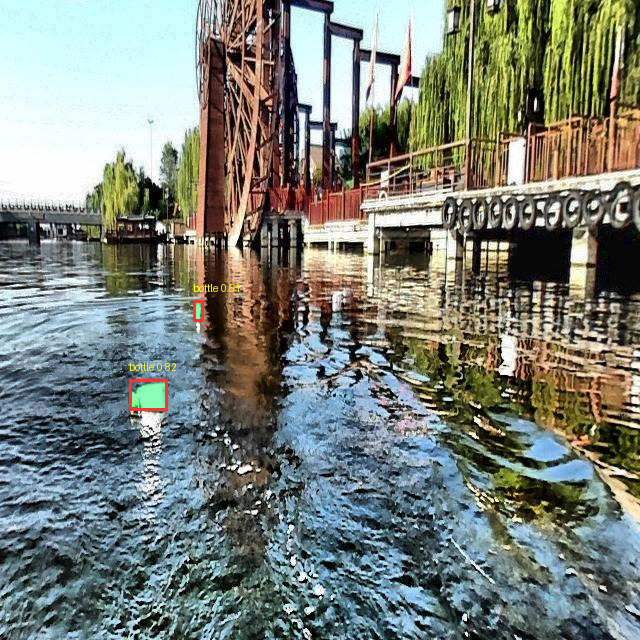

,object_id,class_name,yolo_confidence,sam_predicted_iou,bbox_xyxy,mask_pixels,mask_area_percentage_of_image,mask_path
0,1,bottle,0.817706,0.921875,"[129.52731323242188, 379.5123291015625, 167.89...",956,0.233398,/content/drive/MyDrive/deeplearning/outputs/en...
1,2,bottle,0.510949,0.825530,"[193.163330078125, 300.3960266113281, 203.4055...",139,0.033936,/content/drive/MyDrive/deeplearning/outputs/en...



Image: 000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301.jpg
Bottle detections: 6


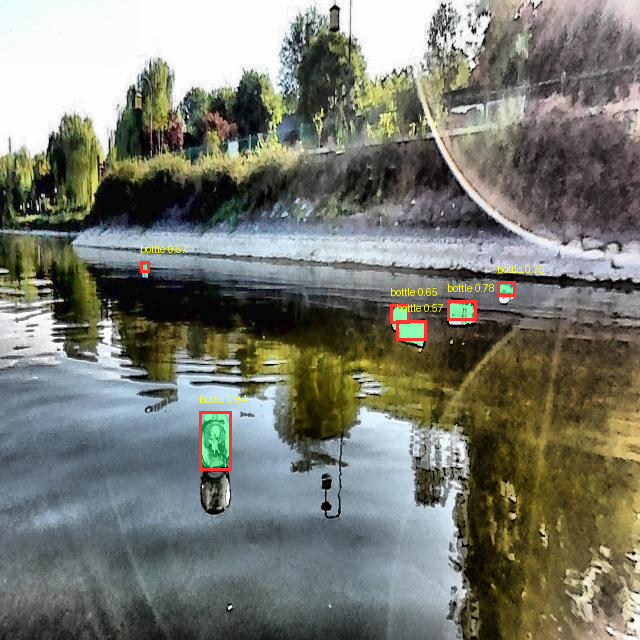

,object_id,class_name,yolo_confidence,sam_predicted_iou,bbox_xyxy,mask_pixels,mask_area_percentage_of_image,mask_path
0,1,bottle,0.837105,0.946722,"[199.73358154296875, 411.1495361328125, 231.55...",1556,0.379883,/content/drive/MyDrive/deeplearning/outputs/en...
1,2,bottle,0.777149,0.903422,"[447.8436279296875, 300.04901123046875, 476.16...",550,0.134277,/content/drive/MyDrive/deeplearning/outputs/en...
2,3,bottle,0.702976,0.845108,"[497.94329833984375, 281.71966552734375, 515.9...",167,0.040771,/content/drive/MyDrive/deeplearning/outputs/en...
3,4,bottle,0.647596,0.874630,"[390.80364990234375, 304.17926025390625, 409.7...",329,0.080322,/content/drive/MyDrive/deeplearning/outputs/en...
4,5,bottle,0.573811,0.895589,"[396.77081298828125, 320.6877746582031, 426.18...",523,0.127686,/content/drive/MyDrive/deeplearning/outputs/en...
5,6,bottle,0.571648,0.804665,"[140.08544921875, 261.2452392578125, 149.54486...",77,0.018799,/content/drive/MyDrive/deeplearning/outputs/en...



Image: 000007_jpg.rf.3532977b58bf11e5c3b0c8577bf22dbc.jpg
Bottle detections: 2


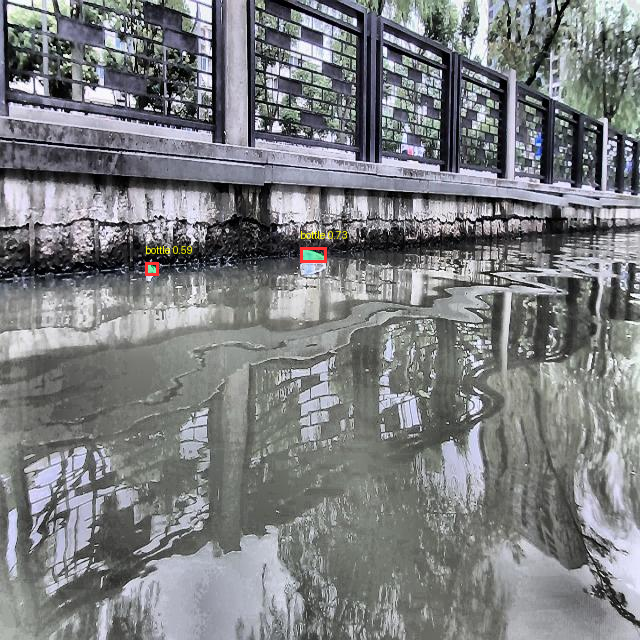

,object_id,class_name,yolo_confidence,sam_predicted_iou,bbox_xyxy,mask_pixels,mask_area_percentage_of_image,mask_path
0,1,bottle,0.73188,0.885295,"[300.11474609375, 247.746826171875, 326.855712...",278,0.067871,/content/drive/MyDrive/deeplearning/outputs/en...
1,2,bottle,0.59370,0.785572,"[145.6563720703125, 262.08941650390625, 158.55...",118,0.028809,/content/drive/MyDrive/deeplearning/outputs/en...


In [9]:
from IPython.display import display

for result in pipeline_results:
    print("\nImage:", result["image_path"].name)
    print("Bottle detections:", result["detection_count"])

    with Image.open(result["annotated_path"]) as im:
        display(im.copy())

    if result["detections"]:
        display(pd.DataFrame(result["detections"]))
    else:
        print("No bottles detected in this image.")

In [10]:
summary_rows = []

for result in pipeline_results:
    if not result["detections"]:
        summary_rows.append({
            "image": result["image_path"].name,
            "object_id": None,
            "class_name": None,
            "yolo_confidence": None,
            "sam_predicted_iou": None,
            "mask_pixels": None,
            "mask_area_percentage_of_image": None,
        })
        continue

    for detection in result["detections"]:
        summary_rows.append({
            "image": result["image_path"].name,
            **detection,
        })

summary_df = pd.DataFrame(summary_rows)

CSV_PATH = OUTPUT_DIR / "end_to_end_results.csv"
summary_df.to_csv(CSV_PATH, index=False)

display(summary_df)

print("CSV saved to:", CSV_PATH)

,image,object_id,class_name,yolo_confidence,sam_predicted_iou,bbox_xyxy,mask_pixels,mask_area_percentage_of_image,mask_path
0,000167_jpg.rf.6001c9af00de6171be294e667851264a...,1,bottle,0.817706,0.921875,"[129.52731323242188, 379.5123291015625, 167.89...",956,0.233398,/content/drive/MyDrive/deeplearning/outputs/en...
1,000167_jpg.rf.6001c9af00de6171be294e667851264a...,2,bottle,0.510949,0.825530,"[193.163330078125, 300.3960266113281, 203.4055...",139,0.033936,/content/drive/MyDrive/deeplearning/outputs/en...
2,000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301...,1,bottle,0.837105,0.946722,"[199.73358154296875, 411.1495361328125, 231.55...",1556,0.379883,/content/drive/MyDrive/deeplearning/outputs/en...
3,000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301...,2,bottle,0.777149,0.903422,"[447.8436279296875, 300.04901123046875, 476.16...",550,0.134277,/content/drive/MyDrive/deeplearning/outputs/en...
4,000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301...,3,bottle,0.702976,0.845108,"[497.94329833984375, 281.71966552734375, 515.9...",167,0.040771,/content/drive/MyDrive/deeplearning/outputs/en...
5,000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301...,4,bottle,0.647596,0.874630,"[390.80364990234375, 304.17926025390625, 409.7...",329,0.080322,/content/drive/MyDrive/deeplearning/outputs/en...
6,000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301...,5,bottle,0.573811,0.895589,"[396.77081298828125, 320.6877746582031, 426.18...",523,0.127686,/content/drive/MyDrive/deeplearning/outputs/en...
7,000029_jpg.rf.7ef8f22f5e45469d2f1cadf55adc5301...,6,bottle,0.571648,0.804665,"[140.08544921875, 261.2452392578125, 149.54486...",77,0.018799,/content/drive/MyDrive/deeplearning/outputs/en...
8,000007_jpg.rf.3532977b58bf11e5c3b0c8577bf22dbc...,1,bottle,0.731880,0.885295,"[300.11474609375, 247.746826171875, 326.855712...",278,0.067871,/content/drive/MyDrive/deeplearning/outputs/en...
9,000007_jpg.rf.3532977b58bf11e5c3b0c8577bf22dbc...,2,bottle,0.593700,0.785572,"[145.6563720703125, 262.08941650390625, 158.55...",118,0.028809,/content/drive/MyDrive/deeplearning/outputs/en...


CSV saved to: /content/drive/MyDrive/deeplearning/outputs/end_to_end/end_to_end_results.csv


In [11]:
from datetime import datetime

run_report = {
    "project": "Plastic Waste Detection and Segmentation",
    "detector": "YOLOv8m",
    "segmenter": "SAM 2.1 Small",
    "device": DEVICE,
    "images_processed": len(pipeline_results),
    "total_detections": sum(
        result["detection_count"] for result in pipeline_results
    ),
    "annotated_output_directory": str(ANNOTATED_DIR),
    "mask_output_directory": str(MASKS_DIR),
    "metadata_output_directory": str(METADATA_DIR),
    "results_csv": str(CSV_PATH),
    "timestamp": datetime.now().isoformat(timespec="seconds"),
}

REPORT_PATH = OUTPUT_DIR / "run_report.json"

with open(REPORT_PATH, "w") as f:
    json.dump(run_report, f, indent=4)

print(json.dumps(run_report, indent=4))
print("\nReport saved to:", REPORT_PATH)

{
    "project": "Plastic Waste Detection and Segmentation",
    "detector": "YOLOv8m",
    "segmenter": "SAM 2.1 Small",
    "device": "cpu",
    "images_processed": 3,
    "total_detections": 10,
    "annotated_output_directory": "/content/drive/MyDrive/deeplearning/outputs/end_to_end/annotated",
    "mask_output_directory": "/content/drive/MyDrive/deeplearning/outputs/end_to_end/masks",
    "metadata_output_directory": "/content/drive/MyDrive/deeplearning/outputs/end_to_end/metadata",
    "results_csv": "/content/drive/MyDrive/deeplearning/outputs/end_to_end/end_to_end_results.csv",
    "timestamp": "2026-10-11T18:18:26"
}

Report saved to: /content/drive/MyDrive/deeplearning/outputs/end_to_end/run_report.json
